# _Merton with mismatch risk: the Base Case_

In [70]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Conceptual description
The pension entitlement of one cohort, i.e. $P_t$: the yearly benefit at time t capital can buy, is only affected by mismatch risk. In the base case equity risk is neglected ($\theta_E = 0$). 

The cohort is fully protected against changes in interest rates and therefore changes in the annuity factor ($\beta = 1$). Mismatch risk is fully borne by the cohort of which the lifecycle is evaluated ($\omega = \beta = 1$). Hence, a fully prottected cohort with no equity exposure is evaluated. Changes in pension entitlements can only be attributed to changes in mismatch risk, which is in turn assumed to be driven by cash-drag and spread-risk dynamics.

Furthermore, the lifecycle starts with $P_0 = 1$ capital, no premiums are contributed during the working period and person's retirement age is T (i.e. working period: $[x_S, \dots, x_R=T])$, after which each year same entitlement is paid out. Therefore, the base case investigates the stylistic (myopic) scenario of what happens with $P_0$ of pension capital in case of only mismatch risk.

## Model and variables

#### _Lifecycle and individual parameters_

- $t \in [0,T]$: time (years)
- $\Delta_t$: time interval
- $T$: retirement age

#### _State variables_

- $P_t$: entitlement, i.e. yearly benefit capital buys
- $s_t$: swap spread, i.e. bond yield minus swap rate of same maturity

#### _Economic variables_

- $R_t^M$: mismatch return, i.e. overlay return minus protection return
- $x_{B,t}$: fraction of protected capital allocated in bonds
- $x_{C,t} = 1 - x_{B,t}$: fraction of protected capital allocated in money market fund, subject to cash drag
- $\delta$: cash drag, i.e. 6m-Euribor minus MMF, historically $25 bps$
- $\bar{s}, \kappa, \sigma_s$: long-run level, mean-reversion speed, and volatility of swap spread $s_t$
- $D_s$: spread duration of the bond
- $\gamma$: relative risk aversion
- $W_t$: Brownian motion, increments are distributed as N(0,$\Delta_t$)
- $M$: number of simulations

####  _Model_
$\max_{\{x_{B,t}\}_{t\in[0,T]}} \mathbb{E}_0 \left[\frac{P_T^{1-\gamma}}{1-\gamma}\right]$

$dP_t = P_t dR_t^M$

With, $dR^M_t = \big(s_t\,x_{B,t} - \delta\,x_{C,t}\big)\,dt - x_{B,t}\,D_s\,ds_t$, $\quad$ and;

$ds_t = \kappa(\bar s - s_t)\,dt + \sigma_s\,dW^s_t$ 

In this initial version of the base case, two policies from Ernsting et al. (2025) are compared, serving as benchmark for a potential optimal policy $x_B^*$. Additionally, an adaptive version of the second policy is tried accounting for negative spread:
1. no spread risk: $x_{B,t} = 0$
2. spread risk to compensate cash drag; $x_{B,t} = \delta / (s_t + \delta)$
3. adaptive approach: spread risk to compensate cash drag; $x_{B,t} = \delta / (s_t + \delta)$ if $s_t \geq 0$, and $x_{B,t} = 0$ if $s_t < 0$


### Specifying parameters

Note: parameters regarding swap spread are subject to change, currently they are just illustrative values. For example, the $ds_t$ Ornstein-Uhlenbeck process could calibrated to market data, or be parametrized to represent an adverse market scenario.

In [71]:
Delta_t = 1
age_start = 25
age_retire = 68
T = age_retire - age_start

delta = 0.0025
s_bar = 0.0030
kappa = 0.30
sigma_s = 0.0025
gamma = 5

P_0 = 1
s_0 = s_bar

M = 10000
N = int(T / Delta_t)
rng = np.random.default_rng(1)

In [72]:
age = np.zeros(N+1)
for i in range(N+1):
    age[i] = int(age_start + i * Delta_t)

### Discretization code: Euler approximation


For $Z_{i+1} \overset{\mathrm{i.i.d.}}{\sim} \mathcal{N}(0,1)$ and $i = 0,\dots,T$:

1. $s_{i+1} = s_i + \kappa(\bar{s} - s_i)\Delta_t + \sigma_s\sqrt{\Delta_t}\,Z_{i+1}$
2. $x_i = \operatorname{policy}(s_i)$
3. $R_{i+1}^{M} = \bigl(x_i s_i - \delta(1-x_i)\bigr)\Delta_t - x_i D_s(s_{i+1} - s_i)$
4. $P_{i+1} = P_i\bigl(1 + R_{i+1}^{M}\bigr)$

Duration calculation for the spread of a _constant maturity bond_, for derivation see Overleaf doc

In [73]:
z = 0.025
maturity = 10
y = z + s_bar
D_s = (1 - (1+y) ** (-maturity)) / y
D_s

8.617933925671089

Initiate the objects for Euler discretization

In [74]:
s = np.zeros((M, N+1))

R1 = np.zeros((M, N+1))
P1 = np.zeros((M, N+1))
R2 = np.zeros((M, N+1))
P2 = np.zeros((M, N+1))

Z = rng.standard_normal((M, N+1))

### **Policy 1**: no spread risk

In [75]:
x_policy1 = np.zeros((M, N+1))
    
for i in range(M):
    for j in range(N+1):
        if j == 0:
            s[i][j] = s_0
            R1[i][j] = 0
            P1[i][j] = P_0
        else:
            s[i][j] = (
                s[i][j-1]
                + kappa * (s_bar - s[i][j-1]) * Delta_t
                + sigma_s * np.sqrt(Delta_t) * Z[i][j]
            ) # note that in policy 1 the s variable cancels out in R due to x = 0, however, it is already simulated here

            R1[i][j] = (
                (x_policy1[i][j-1] * s[i][j-1] - delta * (1 - x_policy1[i][j-1])) * Delta_t
                - x_policy1[i][j-1] * D_s * (s[i][j] - s[i][j-1])
            )

            P1[i][j] = (
                P1[i][j-1] * (1 + R1[i][j])
            )

Charts Policy 1

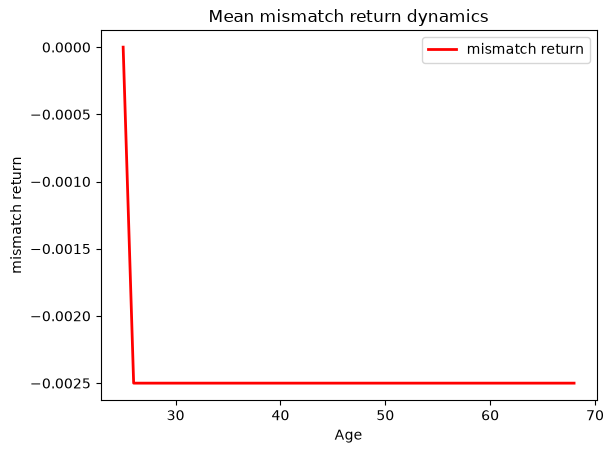

In [76]:
plt.plot(age, np.mean(R1, axis = 0), color="r", linewidth=2, label="mismatch return")
plt.xlabel("Age")
plt.ylabel("mismatch return")
plt.title("Mean mismatch return dynamics")
plt.legend()
plt.show()

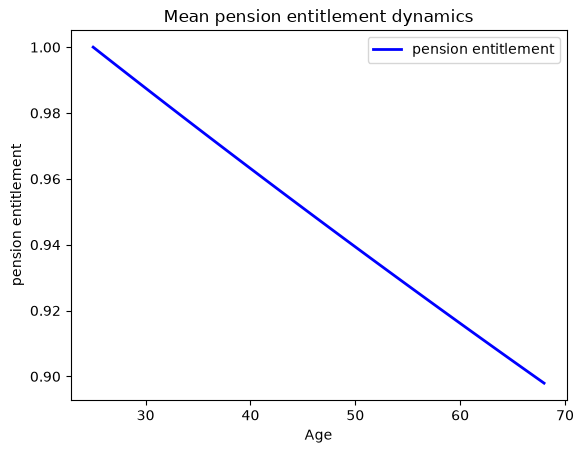

In [77]:
plt.plot(age, np.mean(P1, axis = 0), color="b", linewidth=2, label="pension entitlement")
plt.xlabel("Age")
plt.ylabel("pension entitlement")
plt.title("Mean pension entitlement dynamics")
plt.legend()
plt.show()

### **Policy 3**: spread risk to compensate cash drag

In [78]:
x_policy2 = np.zeros((M, N+1))

for i in range(M):
    for j in range(N+1):
        if j == 0:
            R2[i][j] = 0
            P2[i][j] = P_0
            x_policy2[i][j] = delta /  (s_0 + delta)
        else:
            if s[i][j] >= 0:
                x_policy2[i][j] = delta / (s[i][j] + delta)
            else:
                x_policy2[i][j] = 0

            R2[i][j] = (
                (x_policy2[i][j-1] * s[i][j-1] - delta * (1 - x_policy2[i][j-1])) * Delta_t
                - x_policy2[i][j-1] * D_s * (s[i][j] - s[i][j-1])
            )

            P2[i][j] = (
                P2[i][j-1] * (1 + R2[i][j])
            )

Charts Policy 3

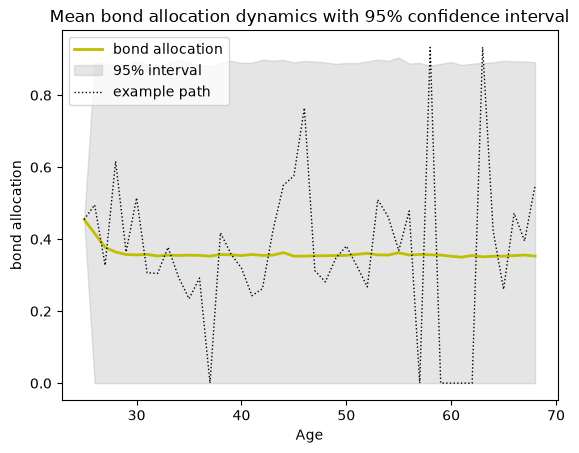

In [79]:
q_lower = np.quantile(x_policy2, 0.025, axis=0)
q_upper = np.quantile(x_policy2, 0.975, axis=0)

plt.plot(age, np.mean(x_policy2, axis = 0), color="y", linewidth=2, label="bond allocation")
plt.fill_between(age, q_lower, q_upper, color="grey", alpha=0.2, label="95% interval")
plt.plot(age, x_policy2[546], color="k", linestyle='dotted', linewidth=1, label="example path")
plt.xlabel("Age")
plt.ylabel("bond allocation")
plt.title("Mean bond allocation dynamics with 95% confidence interval")
plt.legend(loc="upper left")
plt.show()

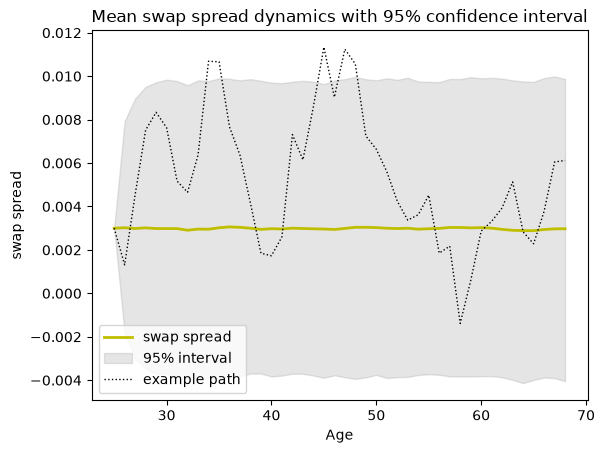

In [80]:
q_lower = np.quantile(s, 0.025, axis=0)
q_upper = np.quantile(s, 0.975, axis=0)

plt.plot(age, np.mean(s, axis = 0), color="y", linewidth=2, label="swap spread")
plt.fill_between(age, q_lower, q_upper, color="grey", alpha=0.2, label="95% interval")
plt.plot(age, s[10], color="k", linestyle='dotted', linewidth=1, label="example path")
plt.xlabel("Age")
plt.ylabel("swap spread")
plt.title("Mean swap spread dynamics with 95% confidence interval")
plt.legend()
plt.show()

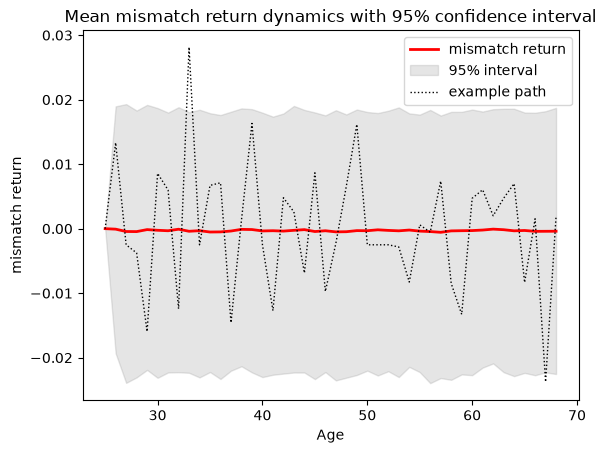

In [81]:
q_lower = np.quantile(R2, 0.025, axis=0)
q_upper = np.quantile(R2, 0.975, axis=0)

plt.plot(age, np.mean(R2, axis = 0), color="r", linewidth=2, label="mismatch return")
plt.fill_between(age, q_lower, q_upper, color="grey", alpha=0.2, label="95% interval")
plt.plot(age, R2[6], color="k", linestyle='dotted', linewidth=1, label="example path")
plt.xlabel("Age")
plt.ylabel("mismatch return")
plt.title("Mean mismatch return dynamics with 95% confidence interval")
plt.legend()
plt.show()

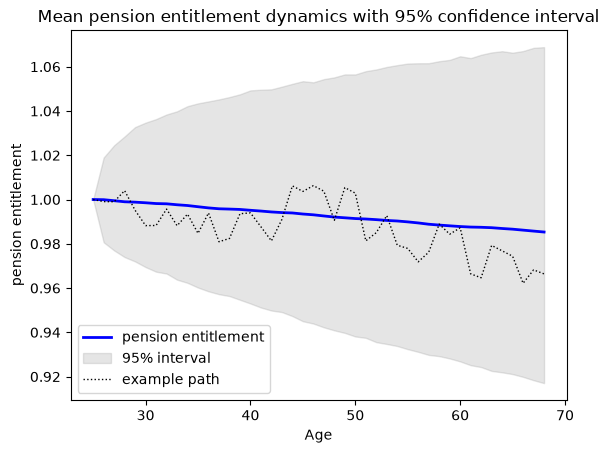

In [82]:
q_lower = np.quantile(P2, 0.025, axis=0)
q_upper = np.quantile(P2, 0.975, axis=0)

plt.plot(age, np.mean(P2, axis = 0), color="b", linewidth=2, label="pension entitlement")
plt.fill_between(age, q_lower, q_upper, color="grey", alpha=0.2, label="95% interval")
plt.plot(age, P2[1], color="k", linestyle='dotted', linewidth=1, label="example path")
plt.xlabel("Age")
plt.ylabel("pension entitlement")
plt.title("Mean pension entitlement dynamics with 95% confidence interval")
plt.legend()
plt.show()

### Certainty equivalent

The certainty equivalent, i.e. the certain entitlement providing the same utility as the uncertain retirement entitlement, follows directly from the objective.

CRRA utility function has the form: $u(P_T) = \frac{P_T^{1-\gamma}}{1-\gamma}$

Mathematical definition of DE: $u(CE) = \mathbb{E}[u(P_T)] \implies CE = u^{-1}\left(\mathbb{E}[u(P_T)]\right)$

Substituting CRRA utility function in the above and rearranging gives

$$
\boxed{
CE = \left(\mathbb{E}\left[P_T^{1-\gamma}\right]\right)^{1/(1-\gamma)}
}.
$$

In [83]:
U1 = np.mean(P1[:, -1] ** (1 - gamma)) 
U2 = np.mean(P2[:, -1] ** (1 - gamma)) 

CE1 = U1 ** (1 / (1 - gamma))
CE2 = U2 ** (1 / (1 - gamma))

print("Certainty equivalent policy 1:", CE1)
print("Mean retirement policy 1:", np.mean(P1[:, -1]))

print("\nCertainty equivalent policy 2:", CE2)
print("Mean retirement policy 2:", np.mean(P2[:, -1]))

Certainty equivalent policy 1: 0.8979556500433594
Mean retirement policy 1: 0.8979556500433593

Certainty equivalent policy 2: 0.9816310892304272
Mean retirement policy 2: 0.9853200800193311


### CE-equivalent mismatch
The CE is expressed in entitlement units at retirement, which is hard to compare with the cash drag value in bps $\delta$. Therefore, the certain yearly mismatch return that gives the same retirement entitlement can be derived from CE: 
$$P_0(1 + r^{CE}_{policy \space i})^T = CE \implies r^{CE}_{policy \space i} = \left(\frac{CE}{P_0}\right)^{1/T} - 1$$

This in turn can be compared with the cash drag ($= r^{CE}_{policy \space 1}$), to see how a policy leads to efficiency gains.

In [84]:
r_CE1 = (CE1 / P_0) ** (1 / T) - 1
r_CE2 = (CE2 / P_0) ** (1 / T) - 1

print("CE-equivalent mismatch policy 1 (bp/yr):", r_CE1 * 10000)
print("CE-equivalent mismatch policy 1 (bp/yr):", r_CE2 * 10000)

CE-equivalent mismatch policy 1 (bp/yr): -24.999999999999467
CE-equivalent mismatch policy 1 (bp/yr): -4.310632072184184


Average bond allocation / underperformance of policy relative to policy 1

In [85]:
x_mean1 = np.mean(x_policy1[:-1])
x_mean2 = np.mean(x_policy2[:,:-1])

print("Average bond allocation policy 1:", x_mean1)
print("Average bond allocation policy 2:", x_mean2)

policy2_underperformance = np.mean(P2[:, -1] < P1[0, -1])

print("Probability policy 2 ends below policy 1:", policy2_underperformance)

Average bond allocation policy 1: 0.0
Average bond allocation policy 2: 0.35987303427915096
Probability policy 2 ends below policy 1: 0.0038
